In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## reliability-diagram

**Figure 2: Confidence histograms (top) and reliability diagrams (bottom) for a 5-layer LeNet (left) and a 110-layer ResNet (right) on CIFAR-100.** In the histograms the dashed and dotted lines mark accuracy and average confidence; in the reliability diagrams the red bars show the gap between each bin's accuracy and its average confidence, the dashed diagonal marks perfect calibration, and the expected calibration error (ECE) is computed from the plotted bins. The ResNet is more accurate (error 30.6% vs. 44.9%) but overconfident, with an average confidence of 0.884 against an accuracy of 0.705, while LeNet's average confidence (0.500) closely matches its accuracy (0.541).

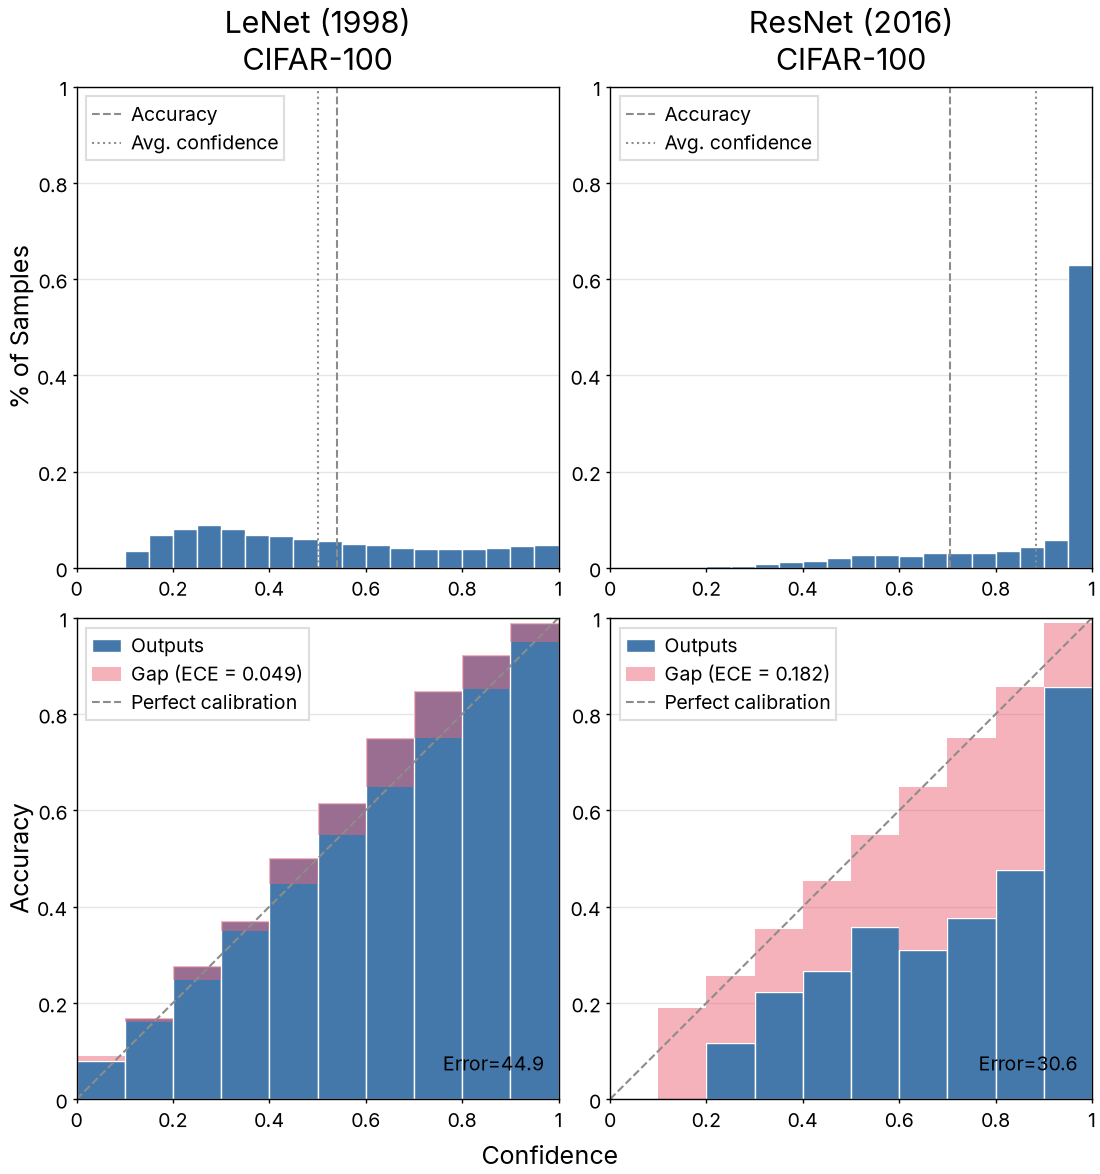

In [2]:
with open("../data/reliability-diagram.json") as f:
    data = json.load(f)

hist_edges = np.array(data["histogram_bin_edges"])
reliability_edges = np.array(data["reliability_bin_edges"])

fig, axes = plt.subplots(2, 2, figsize=(5.5, 3), sharex=True, sharey="row")
for col, model in enumerate(data["models"].values()):
    top, bottom = axes[0, col], axes[1, col]
    top.set_title(f"{model['label']}\n{data['dataset']}")

    top.bar(hist_edges[:-1], model["fraction_of_samples_per_bin"], width=np.diff(hist_edges), align="edge",
            color=colors["series-1"], edgecolor="white", linewidth=0.5)
    top.axvline(model["accuracy_line"], color=colors["neutral"], linestyle="--", linewidth=paper.dashed_width, label="Accuracy")
    top.axvline(model["avg_confidence_line"], color=colors["neutral"], linestyle=":", linewidth=paper.dashed_width, label="Avg. confidence")
    top.grid(axis="x", visible=False)
    top.set_ylim(0, 1)
    top.legend(loc="upper left")

    accuracy = np.array(model["accuracy_per_bin"])
    confidence = np.array(model["avg_confidence_per_bin"])
    # each reliability bin covers two histogram bins, so its share of samples is their sum
    sample_fraction = np.add.reduceat(model["fraction_of_samples_per_bin"], np.arange(0, len(hist_edges) - 1, 2))
    ece = np.sum(sample_fraction * np.abs(accuracy - confidence))
    outputs = bottom.bar(reliability_edges[:-1], accuracy, width=np.diff(reliability_edges), align="edge",
                         color=colors["series-1"], edgecolor="white", linewidth=0.5, label="Outputs")
    # half transparent so an underconfident bin's gap, drawn over its accuracy bar, shows both
    gap = bottom.bar(reliability_edges[:-1], confidence - accuracy, bottom=accuracy, width=np.diff(reliability_edges), align="edge",
                     color=colors["series-2"], alpha=0.5, linewidth=0, label=f"Gap (ECE = {ece:.3f})")
    (diagonal,) = bottom.plot([0, 1], [0, 1], color=colors["neutral"], linestyle="--", linewidth=paper.dashed_width, label="Perfect calibration")
    bottom.text(0.97, 0.05, f"Error={model['error_percent']}", transform=bottom.transAxes, ha="right", va="bottom")
    bottom.grid(axis="x", visible=False)
    bottom.set_xlim(0, 1)
    bottom.set_ylim(0, 1)
    bottom.legend(handles=[outputs, gap, diagonal], loc="upper left")

for ax in axes.flat:
    ax.tick_params(labelleft=True, labelbottom=True)
    # "0" instead of "0.0": the x and y zero labels collide at each panel's corner
    ax.xaxis.set_major_formatter("{x:g}")
    ax.yaxis.set_major_formatter("{x:g}")
axes[0, 0].set_ylabel("% of Samples")
axes[1, 0].set_ylabel("Accuracy")
fig.supxlabel("Confidence")

fit_height(fig, axes, aspect=1.0)
fig.savefig("../outputs/reliability-diagram.pdf")
fig.savefig("../outputs/reliability-diagram.png")
plt.show()